# Avalanche Occurrence Prediction – Logistic Regression

**Objective:** predict whether an **avalanche occurs (1)** or not **(0)** on a mountain slope from the **slope angle** and the **fresh snowfall in the last 24 hours**, using **Logistic Regression**.

> ⚠️ **Simulated data.** `Avalanche_Events.csv` is generated by `generate_dataset.py` using a documented, simplified risk rule (seed fixed). Results show how the *method* works, not real avalanche science. Never use this for real safety decisions.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score)

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully

## 2. Load the Dataset

In [2]:
df = pd.read_csv("Avalanche_Events.csv")
df.head()

,Event_ID,Region,Slope_Angle,New_Snowfall_cm,Temperature_C,Avalanche
0,5001,Himalaya,42.2,63.4,-3.5,0
1,5002,Rockies,47.1,28.6,-11.6,1
2,5003,Himalaya,43.2,14.0,-11.5,0
3,5004,Himalaya,26.2,42.1,-8.8,0
4,5005,Rockies,22.9,36.0,-6.2,0


## 3. Data Exploration

In [3]:
print("Shape of dataset:", df.shape)
print()
df.info()

Shape of dataset: (600, 6)

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Event_ID         600 non-null    int64  
 1   Region           600 non-null    str    
 2   Slope_Angle      600 non-null    float64
 3   New_Snowfall_cm  600 non-null    float64
 4   Temperature_C    600 non-null    float64
 5   Avalanche        600 non-null    int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 28.3 KB

In [4]:
df.describe()

,Event_ID,Slope_Angle,New_Snowfall_cm,Temperature_C,Avalanche
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,5300.500000,33.990667,30.143167,-5.399167,0.301667
std,173.349358,7.789455,20.302489,4.804114,0.459364
min,5001.000000,15.000000,0.800000,-20.200000,0.000000
25%,5150.750000,29.000000,15.050000,-8.800000,0.000000
50%,5300.500000,34.200000,25.700000,-5.400000,0.000000
75%,5450.250000,39.100000,40.900000,-2.200000,1.000000
max,5600.000000,52.000000,100.000000,6.000000,1.000000


## 4. Missing Values and Duplicates

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Event_ID           0
Region             0
Slope_Angle        0
New_Snowfall_cm    0
Temperature_C      0
Avalanche          0
dtype: int64

Duplicate rows: 0

## 5. Exploratory Data Analysis

Avalanche
0    419
1    181
Name: count, dtype: int64

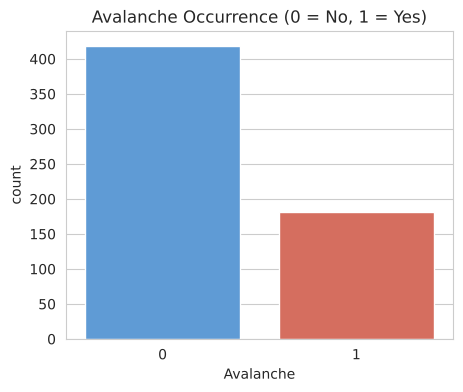

In [6]:
print(df["Avalanche"].value_counts())
plt.figure(figsize=(5, 4))
sns.countplot(x="Avalanche", data=df, hue="Avalanche", palette=["#4C9BE8", "#E8604C"], legend=False)
plt.title("Avalanche Occurrence (0 = No, 1 = Yes)")
plt.show()

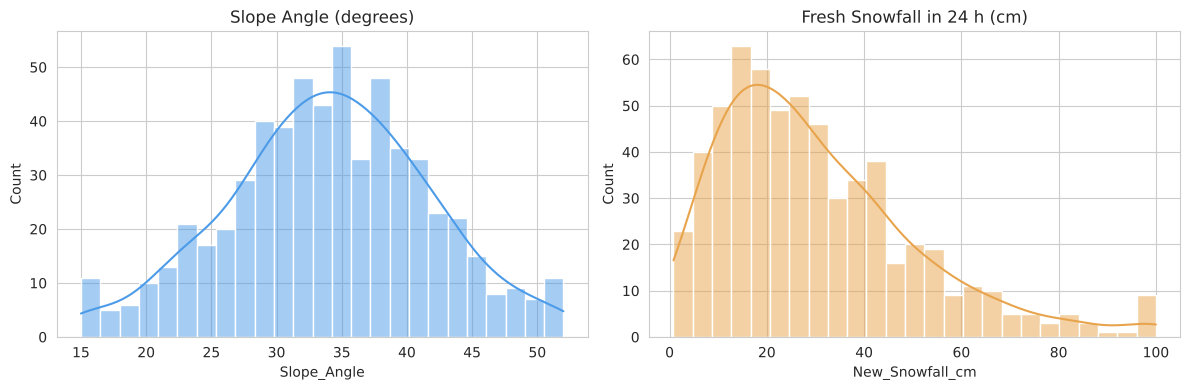

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Slope_Angle"], kde=True, bins=25, ax=axes[0], color="#4C9BE8")
axes[0].set_title("Slope Angle (degrees)")
sns.histplot(df["New_Snowfall_cm"], kde=True, bins=25, ax=axes[1], color="#E8A44C")
axes[1].set_title("Fresh Snowfall in 24 h (cm)")
plt.tight_layout()
plt.show()

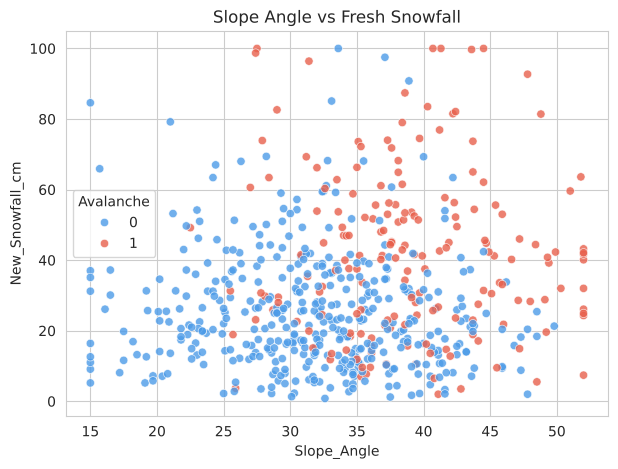

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Slope_Angle", y="New_Snowfall_cm", hue="Avalanche",
                palette=["#4C9BE8", "#E8604C"], alpha=0.8)
plt.title("Slope Angle vs Fresh Snowfall")
plt.show()

Region
Alps        0.238
Andes       0.382
Himalaya    0.270
Rockies     0.317
Name: Avalanche, dtype: float64

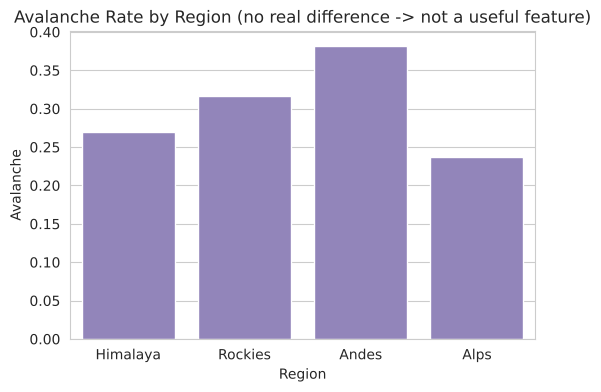

In [9]:
print(df.groupby("Region")["Avalanche"].mean().round(3))
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Region", y="Avalanche", color="#8E7CC3", errorbar=None)
plt.title("Avalanche Rate by Region (no real difference -> not a useful feature)")
plt.show()

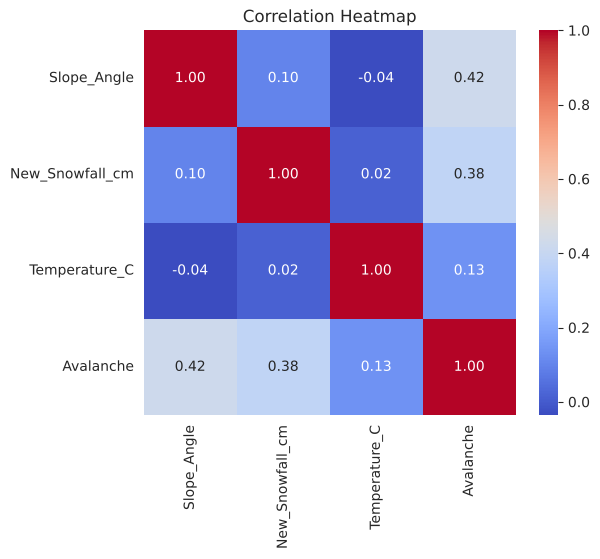

In [10]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Slope_Angle", "New_Snowfall_cm", "Temperature_C", "Avalanche"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 6. Select Independent and Dependent Variables
`Event_ID` is an identifier, `Region` showed no effect, and `Temperature_C` is left out to keep a 2-D decision boundary.

In [11]:
X = df[["Slope_Angle", "New_Snowfall_cm"]]
y = df["Avalanche"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (600, 2)
y shape: (600,)

## 7. Train-Test Split (80% / 20%)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 480
Testing samples : 120

## 8. Feature Scaling

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training mean:", X_train_scaled.mean(axis=0).round(3))
print("Scaled training std :", X_train_scaled.std(axis=0).round(3))

Scaled training mean: [ 0. -0.]
Scaled training std : [1. 1.]

## 9. Train the Logistic Regression Model

In [14]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
print("Coefficients (Slope, Snowfall):", model.coef_[0].round(4))
print("Intercept:", model.intercept_.round(4))

Coefficients (Slope, Snowfall): [1.1991 0.8963]
Intercept: [-1.1664]

## 10. Predictions on Test Data

In [15]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred,
                        "Prob_Avalanche": y_prob.round(3)})
results.head(10)

,Actual,Predicted,Prob_Avalanche
0,0,1,0.730
1,1,1,0.892
2,1,1,0.520
3,1,0,0.234
4,0,0,0.233
5,0,0,0.299
6,1,0,0.214
7,1,1,0.814
8,1,0,0.460
9,0,0,0.040


## 11. Model Evaluation

In [16]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC AUC   : {auc:.4f}")

Accuracy  : 0.8167
Precision : 0.7917
Recall    : 0.5278
F1 Score  : 0.6333
ROC AUC   : 0.8409

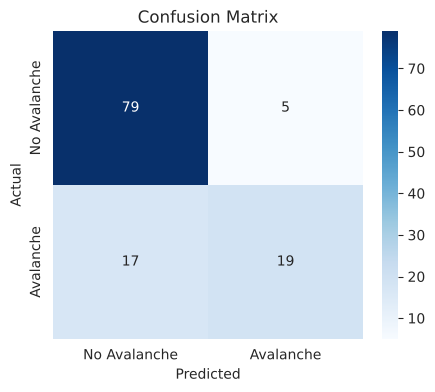

In [17]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Avalanche", "Avalanche"], yticklabels=["No Avalanche", "Avalanche"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

In [18]:
print(classification_report(y_test, y_pred, target_names=["No Avalanche", "Avalanche"]))

              precision    recall  f1-score   support

No Avalanche       0.82      0.94      0.88        84
   Avalanche       0.79      0.53      0.63        36

    accuracy                           0.82       120
   macro avg       0.81      0.73      0.76       120
weighted avg       0.81      0.82      0.80       120

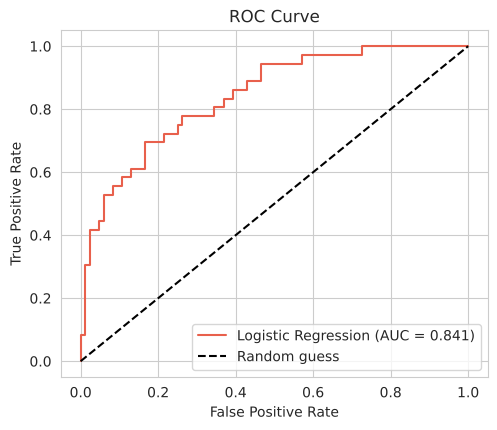

In [19]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})", color="#E8604C")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()

## 12. 5-Fold Cross-Validation
A single split can be lucky or unlucky; cross-validation checks stability.

In [20]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
cv_scores = cross_val_score(pipe, X, y, cv=5, scoring="accuracy")
print("Fold accuracies:", cv_scores.round(3))
print(f"Mean accuracy  : {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

Fold accuracies: [0.842 0.742 0.833 0.833 0.783]
Mean accuracy  : 0.807 (+/- 0.039)

## 13. Decision Boundary Visualization

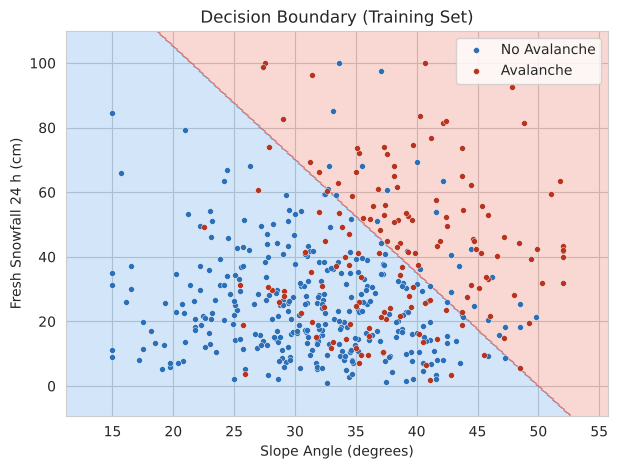

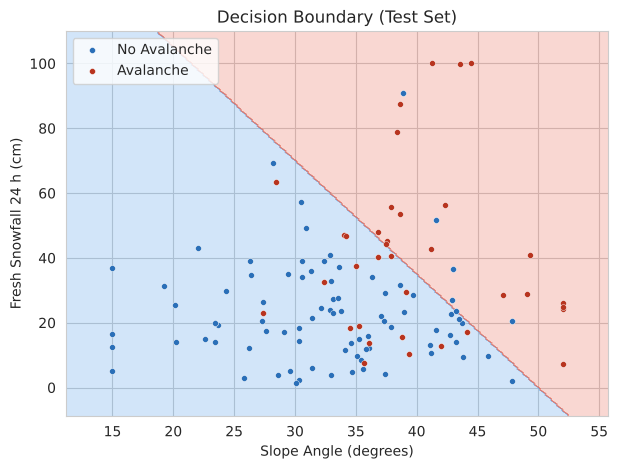

In [21]:
def plot_boundary(X_set, y_set, title):
    x1, x2 = np.meshgrid(
        np.arange(X_set[:, 0].min() - 0.5, X_set[:, 0].max() + 0.5, 0.02),
        np.arange(X_set[:, 1].min() - 0.5, X_set[:, 1].max() + 0.5, 0.02))
    zz = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
    orig = scaler.inverse_transform(np.c_[x1.ravel(), x2.ravel()])   # back to real units
    gx, gy = orig[:, 0].reshape(x1.shape), orig[:, 1].reshape(x1.shape)
    pts = scaler.inverse_transform(X_set)
    plt.figure(figsize=(7, 5))
    plt.contourf(gx, gy, zz, alpha=0.25, cmap=matplotlib.colors.ListedColormap(["#4C9BE8", "#E8604C"]))
    for cls, col, lab in [(0, "#2A6FB8", "No Avalanche"), (1, "#B8341F", "Avalanche")]:
        plt.scatter(pts[y_set.values == cls, 0], pts[y_set.values == cls, 1], c=col, s=18,
                    label=lab, edgecolor="white", linewidth=0.3)
    plt.xlabel("Slope Angle (degrees)"); plt.ylabel("Fresh Snowfall 24 h (cm)")
    plt.title(title); plt.legend()
    plt.show()

plot_boundary(X_train_scaled, y_train, "Decision Boundary (Training Set)")
plot_boundary(X_test_scaled, y_test, "Decision Boundary (Test Set)")

## 14. Predict for New Slopes

In [22]:
new_slopes = pd.DataFrame({"Slope_Angle": [25.0, 38.0, 45.0], "New_Snowfall_cm": [10.0, 40.0, 70.0]})
probs = model.predict_proba(scaler.transform(new_slopes))[:, 1]
new_slopes["Prob_Avalanche"] = probs.round(3)
new_slopes["Predicted"] = (probs >= 0.5).astype(int)
new_slopes

,Slope_Angle,New_Snowfall_cm,Prob_Avalanche,Predicted
0,25.0,10.0,0.031,0
1,38.0,40.0,0.477,0
2,45.0,70.0,0.912,1


## 15. Save the Model and Scaler

In [23]:
joblib.dump(model, "logistic_regression_model.pkl")
joblib.dump(scaler, "standard_scaler.pkl")
loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_scaler = joblib.load("standard_scaler.pkl")
check = loaded_model.predict(loaded_scaler.transform(new_slopes[["Slope_Angle", "New_Snowfall_cm"]]))
print("Saved model + scaler. Reload check predictions:", check)

Saved model + scaler. Reload check predictions: [0 0 1]

## 16. Conclusion
- Steeper slopes and heavier fresh snowfall both raise the predicted avalanche probability, matching the rule used to simulate the data.
- With the classes imbalanced (~30% positives), **recall** and **ROC AUC** are more informative than accuracy alone.
- Because the data is simulated, the model recovering the planted pattern is a *sanity check of the method*, not a scientific finding.
- Next steps: add `Temperature_C`, tune the probability threshold, try `class_weight="balanced"`, compare with tree models.